In [17]:
from google.colab import drive
import zipfile
import shutil
import os

drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Intro to CV/landmark_sift_dataset.zip'
drive_extract_path = '/content/drive/MyDrive/Intro to CV'
drive_dataset_dir = '/content/drive/MyDrive/Intro to CV/Prepared_landmarks'
local_dataset_dir = '/content/Prepared_landmarks'

# Extract on Drive if not already extracted
if not os.path.exists(drive_dataset_dir) and os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(drive_extract_path)

# Copy dataset to Colab local SSD (/content/) for 50x faster disk I/O
if not os.path.exists(local_dataset_dir):
    if os.path.exists(drive_dataset_dir):
        print('Copying dataset from Google Drive to local Colab SSD (/content/Prepared_landmarks)...')
        shutil.copytree(drive_dataset_dir, local_dataset_dir)
        print('Copy complete!')
    elif os.path.exists(zip_path):
        print('Extracting zip directly to local Colab SSD (/content/)...')
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall('/content')
        print('Extraction complete!')
else:
    print('Dataset ready on local Colab SSD at:', local_dataset_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copying dataset from Google Drive to local Colab SSD (/content/Prepared_landmarks)...
Copy complete!


## Task 2: SIFT Feature Extraction


Compute device initialized: cuda
Extracting SIFT features from reference database...
-----------------------------------------------------------------
Landmark: christ_the_reedemer    | Images: 258  | Total Keypoints: 108257
Landmark: eiffel_tower           | Images: 312  | Total Keypoints: 155666
Landmark: great_wall_of_china    | Images: 313  | Total Keypoints: 167482
Landmark: roman_colosseum        | Images: 315  | Total Keypoints: 211448
Landmark: taj_mahal              | Images: 126  | Total Keypoints: 70775
-----------------------------------------------------------------
Database ready in 61.76s! Total reference entries stored: 1321



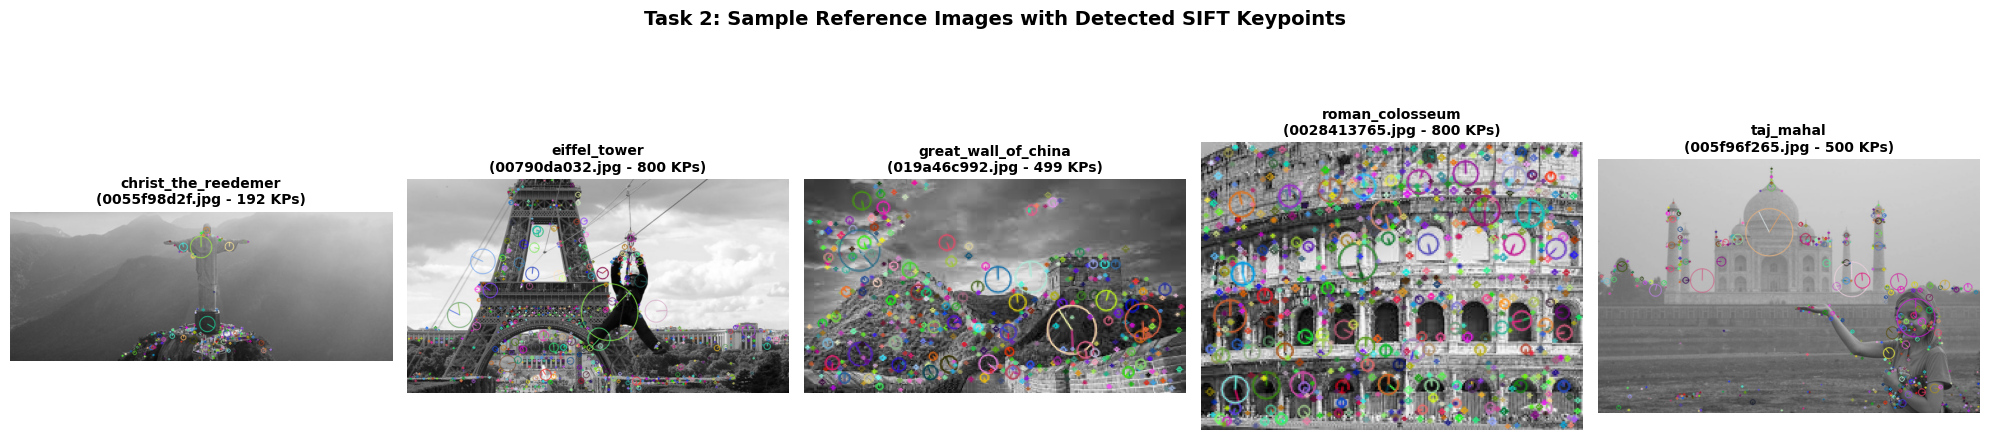

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import time
import pandas as pd
import torch

# Use T4 GPU if available for fast exact Euclidean distance computation in Task 4
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Compute device initialized: {device}')

BASE_DIR = '/content/Prepared_landmarks' if os.path.exists('/content/Prepared_landmarks') else '/content/drive/MyDrive/Intro to CV/Prepared_landmarks'
REF_DIR = os.path.join(BASE_DIR, 'reference')
QUERY_DIR = os.path.join(BASE_DIR, 'query')

# Cap max image dimension to 640px and retain top 800 high-contrast keypoints
MAX_DIM = 640
sift = cv2.SIFT_create(nfeatures=800, contrastThreshold=0.04, edgeThreshold=10)

def load_and_preprocess(img_path, max_dim=MAX_DIM):
    """Loads an image, resizes if larger than max_dim (preserving aspect ratio), and converts to grayscale."""
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        return None, None
    h, w = img_bgr.shape[:2]
    if max(h, w) > max_dim:
        scale = max_dim / float(max(h, w))
        img_bgr = cv2.resize(img_bgr, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return img_bgr, img_gray

reference_db = []
t0 = time.perf_counter()

print('Extracting SIFT features from reference database...\n' + '-' * 65)

landmarks = sorted([d for d in os.listdir(REF_DIR) if os.path.isdir(os.path.join(REF_DIR, d))])
sample_visualizations = []

for landmark in landmarks:
    landmark_path = os.path.join(REF_DIR, landmark)
    image_files = sorted([f for f in os.listdir(landmark_path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))])

    total_kp = 0
    for idx, img_name in enumerate(image_files):
        img_path = os.path.join(landmark_path, img_name)

        # 1. Load each reference image and convert it into grayscale
        img_bgr, img_gray = load_and_preprocess(img_path)
        if img_bgr is None:
            continue

        # 2 & 3. Detect distinctive keypoints and extract feature descriptors
        keypoints, descriptors = sift.detectAndCompute(img_gray, None)

        if descriptors is not None and len(keypoints) >= 4:
            # 5. Store descriptors with corresponding landmark label
            reference_db.append({
                'label': landmark,
                'filename': img_name,
                'filepath': img_path,
                'image_bgr': img_bgr,
                'image_gray': img_gray,
                'keypoints': keypoints,
                'descriptors': descriptors,
                'desc_tensor': torch.from_numpy(descriptors).to(device, dtype=torch.float32)
            })
            total_kp += len(keypoints)

            # Save the first image of each landmark for visualization
            if idx == 0:
                img_kp = cv2.drawKeypoints(
                    img_gray, keypoints, None,
                    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
                )
                sample_visualizations.append((landmark, img_name, len(keypoints), img_kp))

    print(f'Landmark: {landmark:<22} | Images: {len(image_files):<4} | Total Keypoints: {total_kp}')

print('-' * 65)
print(f'Database ready in {time.perf_counter() - t0:.2f}s! Total reference entries stored: {len(reference_db)}\n')

# 4. Display reference images with their detected keypoints (1 sample per class)
fig, axes = plt.subplots(1, len(sample_visualizations), figsize=(20, 5))
if len(sample_visualizations) == 1:
    axes = [axes]

for ax, (label, fname, kp_count, vis_img) in zip(axes, sample_visualizations):
    ax.imshow(cv2.cvtColor(vis_img, cv2.COLOR_BGR2RGB))
    ax.set_title(f'{label}\n({fname} - {kp_count} KPs)', fontsize=10, fontweight='bold')
    ax.axis('off')

plt.suptitle('Task 2: Sample Reference Images with Detected SIFT Keypoints', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Task 3: Query Image Processing

Testing Query Processing on: /content/Prepared_landmarks/query/christ_the_reedemer/00d2585f75.jpg


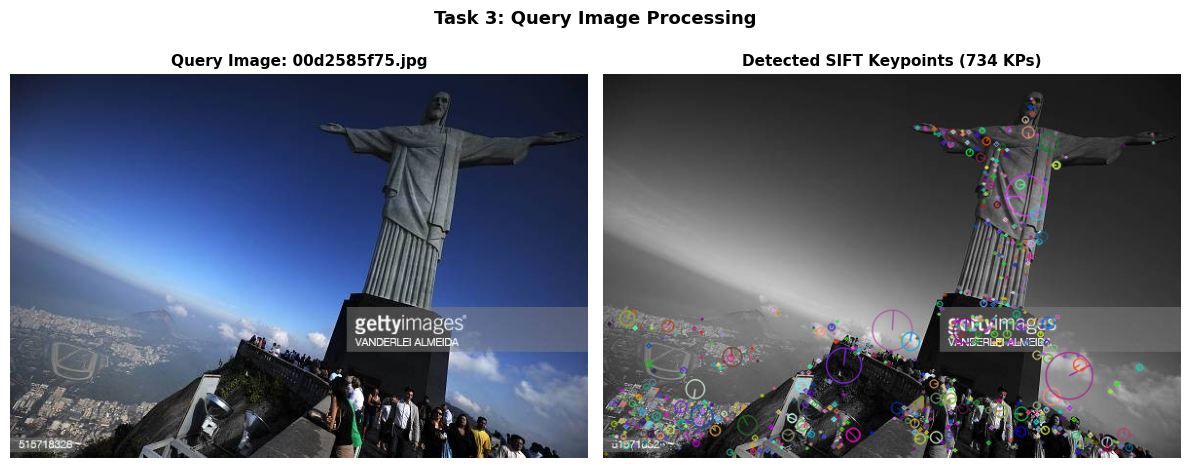

In [19]:
def process_query_image(query_path, display=True):
    """
    Loads a query image, converts it to grayscale, extracts SIFT features,
    and optionally displays the original image alongside its detected keypoints.
    """
    if not os.path.exists(query_path):
        raise FileNotFoundError(f'Query image not found at: {query_path}')

    # 1 & 2. Load the query image and convert into grayscale
    img_bgr, img_gray = load_and_preprocess(query_path)
    if img_bgr is None:
        raise ValueError(f'Failed to decode image at: {query_path}')

    # 3 & 4. Detect SIFT keypoints and extract feature descriptors
    keypoints, descriptors = sift.detectAndCompute(img_gray, None)

    # 5. Display query image with detected keypoints
    if display:
        img_kp = cv2.drawKeypoints(
            img_gray, keypoints, None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
        )

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        axes[0].set_title(f'Query Image: {os.path.basename(query_path)}', fontsize=11, fontweight='bold')
        axes[0].axis('off')

        axes[1].imshow(cv2.cvtColor(img_kp, cv2.COLOR_BGR2RGB))
        axes[1].set_title(f'Detected SIFT Keypoints ({len(keypoints)} KPs)', fontsize=11, fontweight='bold')
        axes[1].axis('off')

        plt.suptitle('Task 3: Query Image Processing', fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.show()

    return img_bgr, img_gray, keypoints, descriptors

# Test Task 3 on a sample query image
sample_query_folders = sorted([d for d in os.listdir(QUERY_DIR) if os.path.isdir(os.path.join(QUERY_DIR, d)) and d != 'unknown'])
sample_folder = os.path.join(QUERY_DIR, sample_query_folders[0])
sample_query_file = os.path.join(sample_folder, sorted(os.listdir(sample_folder))[0])

print(f'Testing Query Processing on: {sample_query_file}')
q_bgr, q_gray, q_kp, q_desc = process_query_image(sample_query_file, display=True)

## Task 4: Feature Matching and Landmark Recognition

In [20]:
# Standard OpenCV Brute-Force Matcher with Euclidean distance (L2 Norm)
bf_matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

# Hyperparameters for Lowe's Ratio Test and Rejection Threshold
LOWE_RATIO = 0.75
MIN_MATCH_THRESHOLD = 12  # Minimum reliable matches to accept recognition

def knn_match_and_ratio_test(q_desc, q_tensor, ref_entry, ratio_thresh=LOWE_RATIO):
    """
    Performs Brute-Force k-NN (k=2) matching with Euclidean distance and Lowe's Ratio Test.
    Uses GPU-accelerated exact L2 distance matrix when CUDA is available, returning standard cv2.DMatch objects.
    """
    if torch.cuda.is_available() and q_tensor is not None and 'desc_tensor' in ref_entry:
        dists = torch.cdist(q_tensor, ref_entry['desc_tensor'], p=2.0)
        if dists.shape[1] < 2:
            return []
        top2_dists, top2_idx = torch.topk(dists, k=2, dim=1, largest=False)
        mask = top2_dists[:, 0] < (ratio_thresh * top2_dists[:, 1])
        valid_q_idx = torch.where(mask)[0].cpu().numpy()
        valid_r_idx = top2_idx[mask, 0].cpu().numpy()
        valid_dists = top2_dists[mask, 0].cpu().numpy()
        return [cv2.DMatch(int(q_i), int(r_i), float(d)) for q_i, r_i, d in zip(valid_q_idx, valid_r_idx, valid_dists)]
    else:
        raw_matches = bf_matcher.knnMatch(q_desc, ref_entry['descriptors'], k=2)
        return [m for match_pair in raw_matches if len(match_pair) == 2 for m, n in [match_pair] if m.distance < ratio_thresh * n.distance]

def recognize_landmark(q_desc, ref_db, q_kp=None, ratio_thresh=LOWE_RATIO, match_thresh=MIN_MATCH_THRESHOLD, verbose=True):
    """
    Compares query descriptors against all entries in the reference database.
    Ranks landmarks by geometrically verified reliable matches and applies a threshold to reject unknown images.
    """
    if q_desc is None or len(q_desc) < 4:
        return 'Unknown / Rejected', 0, None, [], []

    q_tensor = torch.from_numpy(q_desc).to(device, dtype=torch.float32) if torch.cuda.is_available() else None

    landmark_ranking = {}
    for ref_entry in ref_db:
        # 1, 2 & 3. Brute-Force Euclidean k-NN (k=2) + Lowe's Ratio Test
        good_matches = knn_match_and_ratio_test(q_desc, q_tensor, ref_entry, ratio_thresh)

        label = ref_entry['label']
        num_good = len(good_matches)

        # 4. Count reliable matches for each landmark
        if label not in landmark_ranking or num_good > landmark_ranking[label]['best_count']:
            landmark_ranking[label] = {
                'best_count': num_good,
                'total_count': landmark_ranking.get(label, {}).get('total_count', 0) + num_good,
                'best_ref_entry': ref_entry,
                'best_matches': good_matches,
                'inliers': 0
            }
        else:
            landmark_ranking[label]['total_count'] += num_good

    # Compute RANSAC geometric inliers for the top candidate of each landmark class
    if q_kp is not None:
        for label, stats in landmark_ranking.items():
            if stats['best_count'] >= 4:
                ref_kp = stats['best_ref_entry']['keypoints']
                matches = stats['best_matches']
                src_pts = np.float32([ref_kp[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
                dst_pts = np.float32([q_kp[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
                _, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
                if mask is not None:
                    stats['inliers'] = int(np.sum(mask))

    # 5. Rank landmark candidates according to their matching results
    sorted_candidates = sorted(
        landmark_ranking.items(),
        key=lambda item: (
            item[1]['inliers'] if item[1]['inliers'] >= 6 else 0,
            item[1]['best_count'],
            item[1]['total_count']
        ),
        reverse=True
    )

    top_landmark, top_stats = sorted_candidates[0]
    top_match_count = top_stats['best_count']
    best_overall_entry = top_stats['best_ref_entry']
    best_overall_matches = top_stats['best_matches']

    # Apply threshold decision to reject unknown or incorrectly matched images
    if top_match_count >= match_thresh and (q_kp is None or top_stats['inliers'] >= 6):
        predicted_label = top_landmark
        decision = 'Recognized'
    else:
        predicted_label = 'Unknown / Rejected'
        decision = 'Rejected'

    # 6. Display most likely landmark and number of reliable matches
    if verbose:
        print('=' * 78)
        print(f"{'Rank':<5} | {'Landmark Candidate':<22} | {'Reliable Matches':<17} | {'RANSAC Inliers':<15} | {'Total Class Matches'}")
        print('-' * 78)
        for rank, (lm_name, stats) in enumerate(sorted_candidates, 1):
            print(f"{rank:<5} | {lm_name:<22} | {stats['best_count']:<17} | {stats['inliers']:<15} | {stats['total_count']}")
        print('=' * 78)
        print(f'Predicted Landmark : {predicted_label}')
        print(f'Reliable Matches   : {top_match_count} (Threshold = {match_thresh})')
        print(f'Decision Status    : {decision}\n')

    return predicted_label, top_match_count, best_overall_entry, best_overall_matches, sorted_candidates

# Test Task 4 on our sample query image
pred_label, good_count, best_ref, best_matches, ranking = recognize_landmark(q_desc, reference_db, q_kp=q_kp, verbose=True)

# Also test on an 'unknown' query image to verify rejection threshold
unknown_dir = os.path.join(QUERY_DIR, 'unknown')
if os.path.exists(unknown_dir) and len(os.listdir(unknown_dir)) > 0:
    unknown_sample = os.path.join(unknown_dir, sorted(os.listdir(unknown_dir))[0])
    print(f'Testing Rejection Threshold on Unknown Image: {os.path.basename(unknown_sample)}')
    _, _, u_kp, u_desc = process_query_image(unknown_sample, display=False)
    recognize_landmark(u_desc, reference_db, q_kp=u_kp, verbose=True)

Rank  | Landmark Candidate     | Reliable Matches  | RANSAC Inliers  | Total Class Matches
------------------------------------------------------------------------------
1     | christ_the_reedemer    | 137               | 130             | 2891
2     | eiffel_tower           | 42                | 34              | 2181
3     | great_wall_of_china    | 24                | 19              | 1987
4     | taj_mahal              | 32                | 7               | 976
5     | roman_colosseum        | 20                | 5               | 1875
Predicted Landmark : christ_the_reedemer
Reliable Matches   : 137 (Threshold = 12)
Decision Status    : Recognized

Testing Rejection Threshold on Unknown Image: 0016510b5c.jpg
Rank  | Landmark Candidate     | Reliable Matches  | RANSAC Inliers  | Total Class Matches
------------------------------------------------------------------------------
1     | eiffel_tower           | 65                | 7               | 5690
2     | christ_the_reedemer 

**Task 5: Landmark Localization**

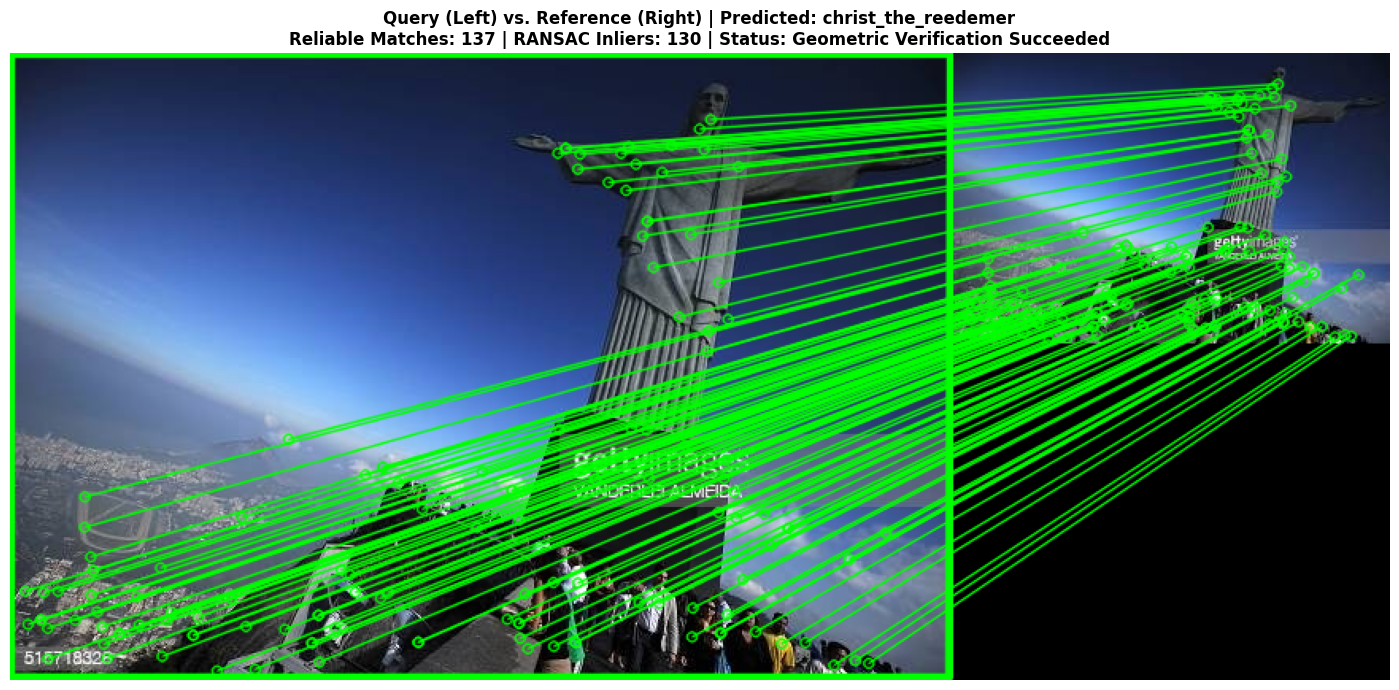

In [21]:
MIN_INLIER_THRESHOLD = 6  # Minimum RANSAC inliers required for reliable geometric localization

def localize_and_visualize(q_bgr, q_kp, best_ref_entry, good_matches, predicted_label, match_thresh=MIN_MATCH_THRESHOLD, display=True):
    """
    Estimates homography using RANSAC, projects reference corners onto the query image,
    validates the geometric transformation, and displays the complete recognition output.
    """
    num_good = len(good_matches)
    inliers_count = 0
    localization_status = 'Localization Failed / Skipped'
    q_localized = q_bgr.copy()
    matches_mask = None

    if predicted_label != 'Unknown / Rejected' and best_ref_entry is not None and num_good >= max(4, match_thresh):
        ref_kp = best_ref_entry['keypoints']
        ref_h, ref_w = best_ref_entry['image_gray'].shape

        # 1. Obtain corresponding keypoint coordinates
        src_pts = np.float32([ref_kp[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_pts = np.float32([q_kp[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)

        # 2. Estimate homography using RANSAC
        H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

        if H is not None and mask is not None:
            matches_mask = mask.ravel().tolist()
            inliers_count = int(np.sum(mask))

            # 3. Project the four corners of the reference image onto the query image
            ref_corners = np.float32([[0, 0], [0, ref_h - 1], [ref_w - 1, ref_h - 1], [ref_w - 1, 0]]).reshape(-1, 1, 2)
            projected_corners = cv2.perspectiveTransform(ref_corners, H)

            # Geometric sanity check: verify enough inliers, convexity, and non-degenerate polygon area
            poly_int = np.int32(projected_corners)
            poly_area = cv2.contourArea(poly_int)
            q_area = q_bgr.shape[0] * q_bgr.shape[1]
            is_convex = cv2.isContourConvex(poly_int)

            if inliers_count >= MIN_INLIER_THRESHOLD and is_convex and (0.005 * q_area < poly_area < 4.5 * q_area):
                # 4. Draw a polygon around the matched landmark region
                cv2.polylines(q_localized, [poly_int], isClosed=True, color=(0, 255, 0), thickness=4, lineType=cv2.LINE_AA)
                localization_status = 'Geometric Verification Succeeded'
            else:
                localization_status = f'Unreliable Geometry (Inliers: {inliers_count}, Convex: {is_convex}) - Polygon Omitted'
        else:
            localization_status = 'Homography Estimation Failed'
    else:
        localization_status = 'Rejected / Insufficient Matches for Localization'

    # 5. Display reliable matches, RANSAC inliers, and localized landmark region
    if display and best_ref_entry is not None:
        draw_params = dict(
            matchColor=(0, 255, 0),
            singlePointColor=None,
            matchesMask=matches_mask,
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )

        # Query image MUST be passed as img1 (left) and Reference image as img2 (right)
        matched_vis = cv2.drawMatches(
            q_localized, q_kp,
            best_ref_entry['image_bgr'], best_ref_entry['keypoints'],
            good_matches, None, **draw_params
        )

        plt.figure(figsize=(16, 7))
        plt.imshow(cv2.cvtColor(matched_vis, cv2.COLOR_BGR2RGB))
        plt.title(
            f'Query (Left) vs. Reference (Right) | Predicted: {predicted_label}\n'
            f'Reliable Matches: {num_good} | RANSAC Inliers: {inliers_count} | Status: {localization_status}',
            fontsize=12, fontweight='bold'
        )
        plt.axis('off')
        plt.tight_layout()
        plt.show()

    return inliers_count, localization_status, q_localized

# Test Task 5 on our sample query image
inliers, loc_status, _ = localize_and_visualize(
    q_bgr, q_kp, best_ref, best_matches, pred_label, display=True
)

## Task 6: Performance Evaluation

Running GPU-accelerated evaluation across 339 query images...
-----------------------------------------------------------------------------------------------
[  1/339] PASS | True: christ_the_reedemer  | File: 00d2585f75.jpg   -> Pred: christ_the_reedemer  (Matches: 137, Inliers: 130, Time: 1.156s)
[  2/339] PASS | True: christ_the_reedemer  | File: 07f0b2ec5b.jpg   -> Pred: christ_the_reedemer  (Matches: 130, Inliers: 128, Time: 0.939s)
[  3/339] PASS | True: christ_the_reedemer  | File: 0ca3b8d570.jpg   -> Pred: christ_the_reedemer  (Matches: 176, Inliers: 175, Time: 0.894s)
[  4/339] PASS | True: christ_the_reedemer  | File: 0d00878384.jpg   -> Pred: christ_the_reedemer  (Matches: 86 , Inliers: 80 , Time: 1.071s)
[  5/339] PASS | True: christ_the_reedemer  | File: 0e0236c5be.jpg   -> Pred: christ_the_reedemer  (Matches: 77 , Inliers: 71 , Time: 1.042s)
[  6/339] PASS | True: christ_the_reedemer  | File: 10d04f4650.jpg   -> Pred: christ_the_reedemer  (Matches: 139, Inliers: 133, Time

,True Landmark,Total_Images,Correct_Predictions,Accuracy_Pct,Avg_Keypoints,Avg_Reliable_Matches,Avg_RANSAC_Inliers,Avg_Time_s
0,christ_the_reedemer,65,59,90.77,461.2,98.3,86.0,1.0668
1,eiffel_tower,79,64,81.01,542.2,84.9,67.1,1.1193
2,great_wall_of_china,79,56,70.89,584.7,102.5,91.3,1.0878
3,roman_colosseum,79,70,88.61,682.0,126.7,114.7,1.0937
4,taj_mahal,32,27,84.38,526.0,102.5,84.4,1.1199
5,unknown,5,0,0.00,540.0,33.0,6.8,1.2564



--- PER-CLASS SUMMARY TABLE (COPY FOR RESULTS.MD) ---
| True Landmark       |   Total_Images |   Correct_Predictions |   Accuracy_Pct |   Avg_Keypoints |   Avg_Reliable_Matches |   Avg_RANSAC_Inliers |   Avg_Time_s |
|:--------------------|---------------:|----------------------:|---------------:|----------------:|-----------------------:|---------------------:|-------------:|
| christ_the_reedemer |             65 |                    59 |          90.77 |           461.2 |                   98.3 |                 86   |       1.0668 |
| eiffel_tower        |             79 |                    64 |          81.01 |           542.2 |                   84.9 |                 67.1 |       1.1193 |
| great_wall_of_china |             79 |                    56 |          70.89 |           584.7 |                  102.5 |                 91.3 |       1.0878 |
| roman_colosseum     |             79 |                    70 |          88.61 |           682   |                  126.7 |      

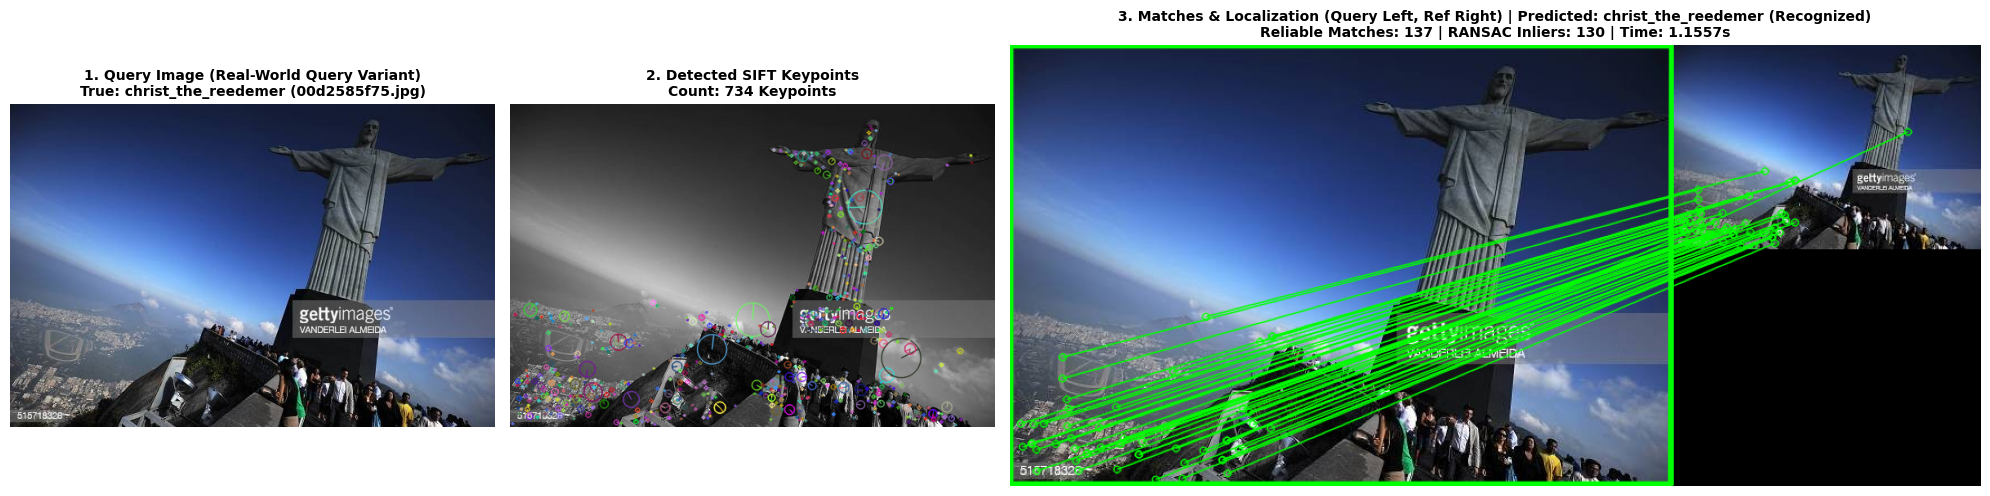

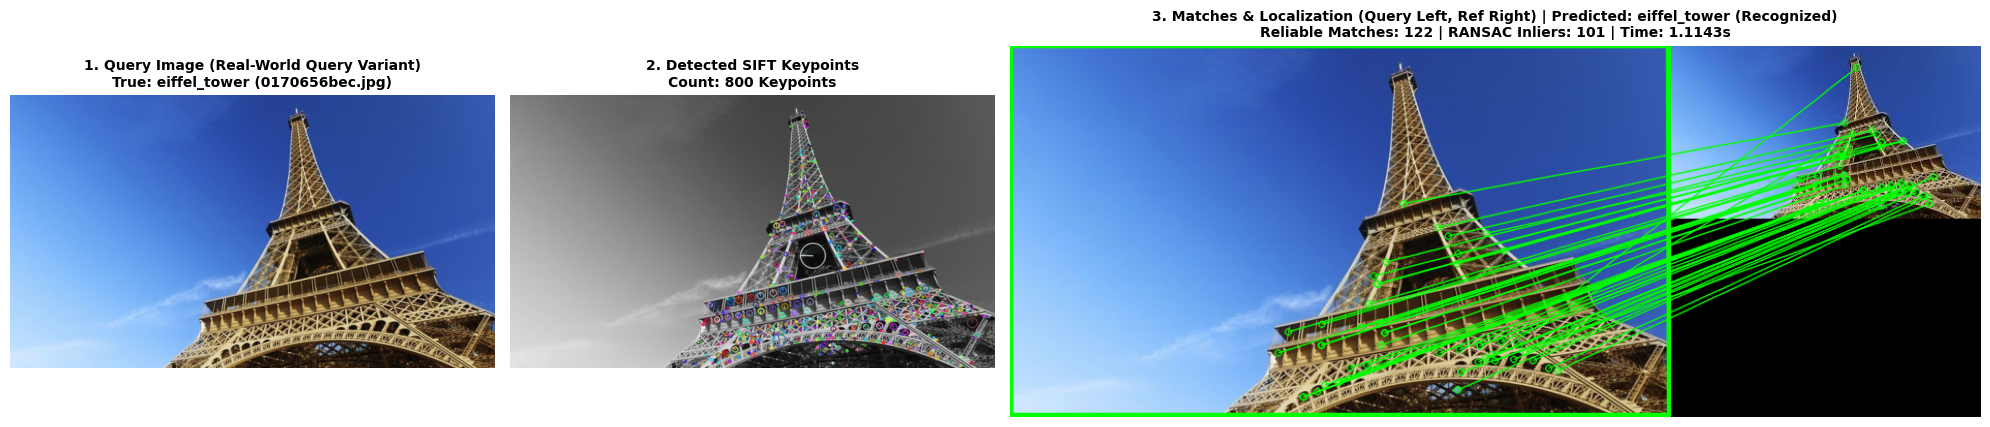

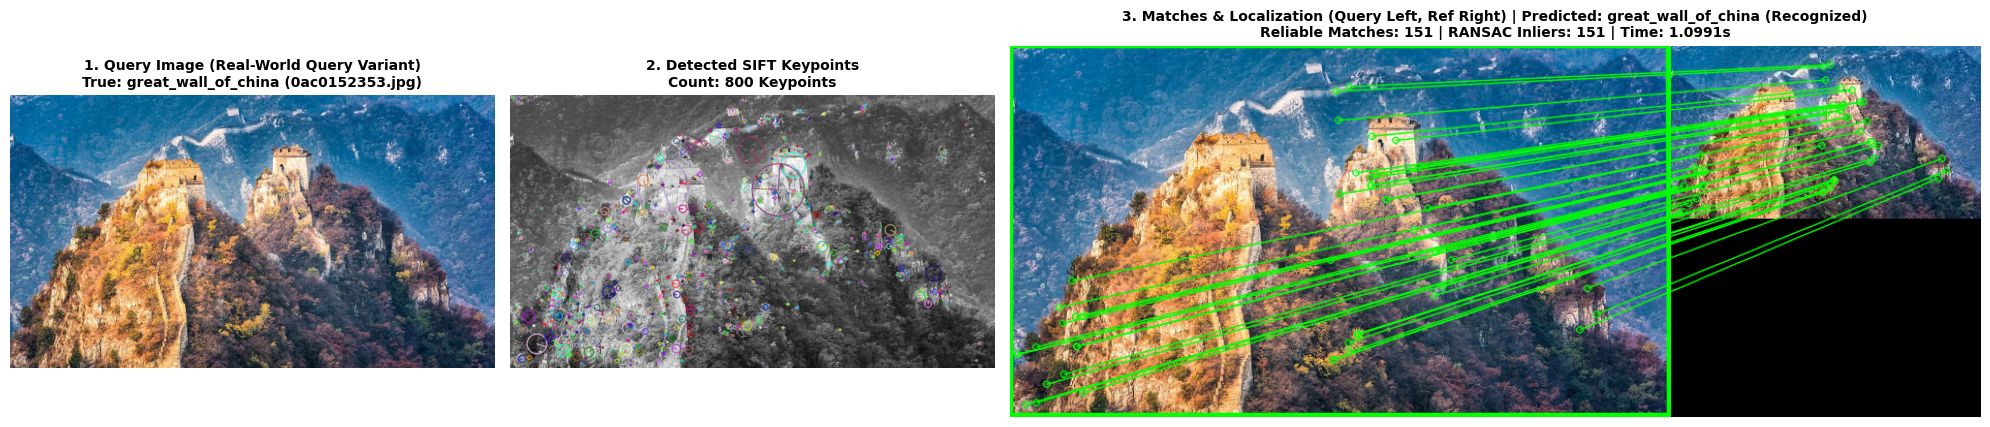

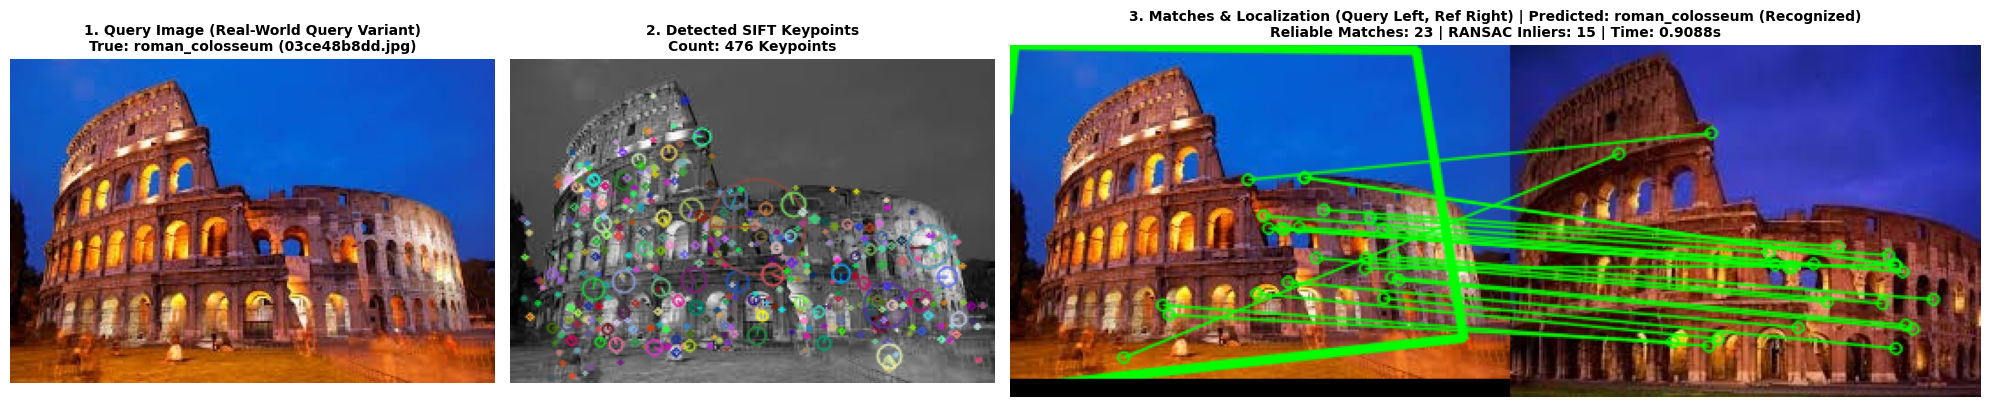

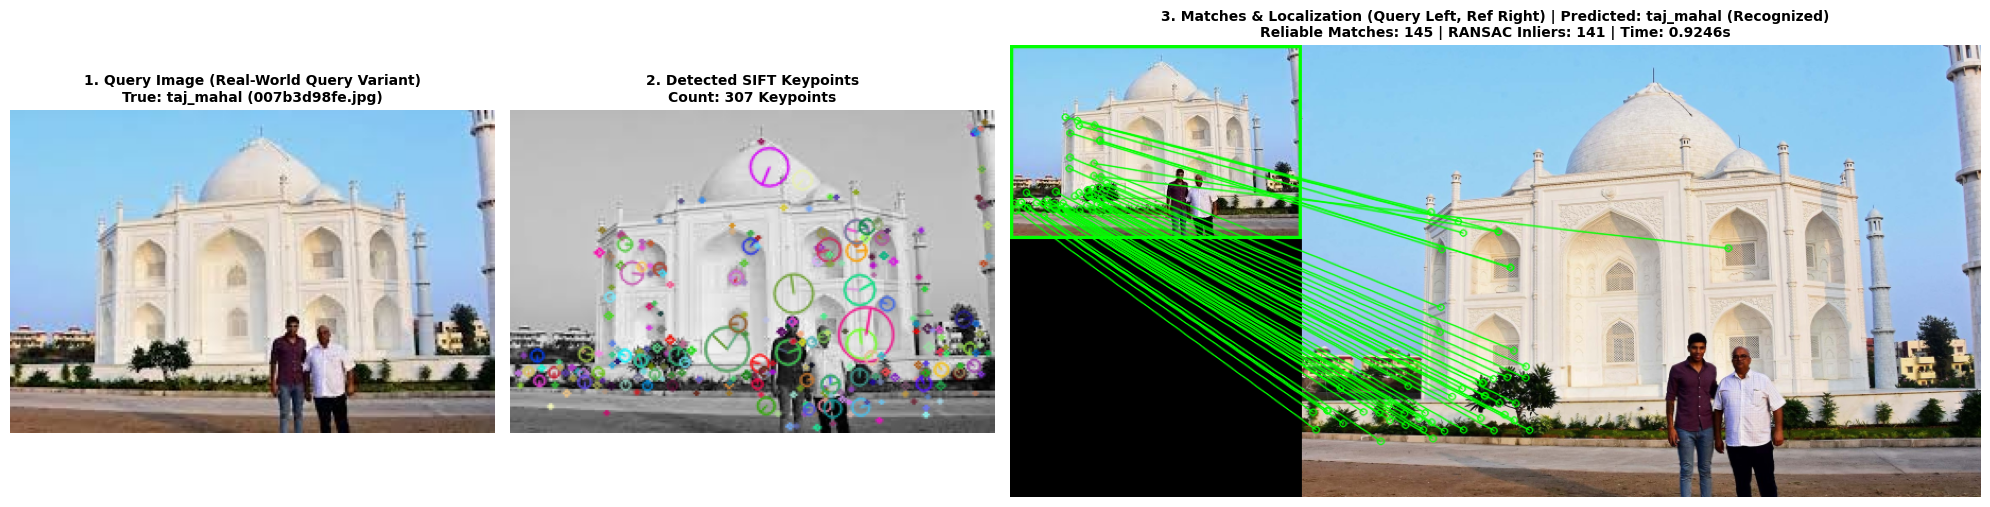

In [22]:
def infer_condition(filename, true_label):
    """Helper to categorize the test condition from the filename or folder."""
    fname = filename.lower()
    if true_label == 'unknown':
        return 'Unknown Landmark'
    elif any(k in fname for k in ['rot', 'angle', 'deg']):
        return 'Rotated'
    elif any(k in fname for k in ['resiz', 'scale', 'small', 'half', 'zoom']):
        return 'Resized'
    elif any(k in fname for k in ['bright', 'dark', 'low', 'illum', 'dim', 'night', 'light']):
        return 'Reduced Brightness'
    elif any(k in fname for k in ['view', 'persp', 'side', 'diff']):
        return 'Different Viewpoint'
    elif any(k in fname for k in ['orig', 'norm', 'base', 'clean']):
        return 'Original'
    else:
        return 'Real-World Query Variant'

evaluation_records = []
visual_showcase_samples = []

query_categories = sorted([d for d in os.listdir(QUERY_DIR) if os.path.isdir(os.path.join(QUERY_DIR, d))])

all_query_tasks = []
for category in query_categories:
    cat_path = os.path.join(QUERY_DIR, category)
    q_files = sorted([f for f in os.listdir(cat_path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))])
    for q_file in q_files:
        all_query_tasks.append((category, q_file, os.path.join(cat_path, q_file)))

print(f'Running GPU-accelerated evaluation across {len(all_query_tasks)} query images...\n' + '-' * 95)

seen_categories_for_plot = set()

for idx, (category, q_file, q_path) in enumerate(all_query_tasks, 1):
    start_time = time.perf_counter()

    # Step 1: Process Query Image
    q_bgr, q_gray, q_kp, q_desc = process_query_image(q_path, display=False)

    # Step 2: Feature Matching & Recognition (with geometric verification)
    pred_label, good_count, best_ref, best_matches, _ = recognize_landmark(
        q_desc, reference_db, q_kp=q_kp, ratio_thresh=LOWE_RATIO, match_thresh=MIN_MATCH_THRESHOLD, verbose=False
    )

    # Step 3: Landmark Localization
    inliers_count, loc_status, q_localized = localize_and_visualize(
        q_bgr, q_kp, best_ref, best_matches, pred_label, match_thresh=MIN_MATCH_THRESHOLD, display=False
    )

    elapsed_time = time.perf_counter() - start_time

    decision = 'Recognized' if pred_label != 'Unknown / Rejected' else 'Rejected'
    is_correct = (decision == 'Rejected') if category == 'unknown' else (pred_label == category)
    condition_type = infer_condition(q_file, category)

    record = {
        'True Landmark': category,
        'Query File': q_file,
        'Condition': condition_type,
        'Query Keypoints': len(q_kp) if q_kp is not None else 0,
        'Reliable Matches': good_count,
        'RANSAC Inliers': inliers_count,
        'Predicted Landmark': pred_label,
        'Decision': decision,
        'Localization Status': loc_status,
        'Correct': is_correct,
        'Processing Time (s)': round(elapsed_time, 4)
    }
    evaluation_records.append(record)

    status_icon = 'PASS' if is_correct else 'FAIL'
    if idx % 20 == 0 or idx <= 10 or idx == len(all_query_tasks):
        print(f'[{idx:>3}/{len(all_query_tasks)}] {status_icon} | True: {category:<20} | File: {q_file:<16} -> Pred: {pred_label:<20} (Matches: {good_count:<3}, Inliers: {inliers_count:<3}, Time: {elapsed_time:.3f}s)')

    # Save 1 representative sample per category for visual showcase
    if category not in seen_categories_for_plot and is_correct:
        seen_categories_for_plot.add(category)
        visual_showcase_samples.append({
            'record': record,
            'q_bgr': q_bgr,
            'q_gray': q_gray,
            'q_kp': q_kp,
            'best_ref': best_ref,
            'best_matches': best_matches,
            'q_localized': q_localized
        })

# Create Evaluation DataFrame
results_df = pd.DataFrame(evaluation_records)

# Calculate overall & per-class metrics
total_queries = len(results_df)
correct_predictions = results_df['Correct'].sum()
overall_accuracy = (correct_predictions / total_queries) * 100 if total_queries > 0 else 0
avg_time = results_df['Processing Time (s)'].mean()

print('\n' + '=' * 105)
print(f'EVALUATION COMPLETE | Total Queries: {total_queries} | Accuracy: {overall_accuracy:.2f}% ({correct_predictions}/{total_queries}) | Avg Time: {avg_time:.4f}s')
print('=' * 105)

# Per-Landmark Summary Table
class_summary = results_df.groupby('True Landmark').agg(
    Total_Images=('Query File', 'count'),
    Correct_Predictions=('Correct', 'sum'),
    Accuracy_Pct=('Correct', lambda x: round(x.mean() * 100, 2)),
    Avg_Keypoints=('Query Keypoints', lambda x: round(x.mean(), 1)),
    Avg_Reliable_Matches=('Reliable Matches', lambda x: round(x.mean(), 1)),
    Avg_RANSAC_Inliers=('RANSAC Inliers', lambda x: round(x.mean(), 1)),
    Avg_Time_s=('Processing Time (s)', lambda x: round(x.mean(), 4))
).reset_index()

display(class_summary)

print('\n--- PER-CLASS SUMMARY TABLE (COPY FOR RESULTS.MD) ---')
print(class_summary.to_markdown(index=False))

print('\n--- SAMPLE DETAILED RECORDS (COPY FOR RESULTS.MD) ---')
sample_detailed = results_df.groupby('True Landmark').head(4)
print(sample_detailed.to_markdown(index=False))
print('--- END OF TABLE OUTPUT ---\n')

# Display the Complete 3-Panel Expected Output for 1 representative sample per category
print(f'Generating Complete Expected Output Visualizations ({len(visual_showcase_samples)} categories)...')
for item in visual_showcase_samples:
    rec = item['record']
    q_bgr = item['q_bgr']
    q_gray = item['q_gray']
    q_kp = item['q_kp']
    best_ref = item['best_ref']
    best_matches = item['best_matches']
    q_loc = item['q_localized']

    fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={'width_ratios': [1, 1, 2]})

    axes[0].imshow(cv2.cvtColor(q_bgr, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"1. Query Image ({rec['Condition']})\nTrue: {rec['True Landmark']} ({rec['Query File']})", fontsize=10, fontweight='bold')
    axes[0].axis('off')

    q_kp_img = cv2.drawKeypoints(q_gray, q_kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    axes[1].imshow(cv2.cvtColor(q_kp_img, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"2. Detected SIFT Keypoints\nCount: {rec['Query Keypoints']} Keypoints", fontsize=10, fontweight='bold')
    axes[1].axis('off')

    if best_ref is not None and len(best_matches) > 0:
        match_vis = cv2.drawMatches(
            q_loc, q_kp,
            best_ref['image_bgr'], best_ref['keypoints'],
            best_matches[:50], None,
            matchColor=(0, 255, 0),
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
        )
        axes[2].imshow(cv2.cvtColor(match_vis, cv2.COLOR_BGR2RGB))
    else:
        axes[2].imshow(cv2.cvtColor(q_loc, cv2.COLOR_BGR2RGB))

    axes[2].set_title(
        f"3. Matches & Localization (Query Left, Ref Right) | Predicted: {rec['Predicted Landmark']} ({rec['Decision']})\n"
        f"Reliable Matches: {rec['Reliable Matches']} | RANSAC Inliers: {rec['RANSAC Inliers']} | Time: {rec['Processing Time (s)']}s",
        fontsize=10, fontweight='bold'
    )
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()